# Practical tasks

##### Please explore the datasets and answer the questions below.
##### Here are some guidlines and advices you should consider:
* you can add as many cells as is comfortable for you for each answer
* some questions require your explanation. Add a cell and choose a markdown option in the menu 
* when you are making plots, please add labels to the axes

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

import seaborn as sns
from sklearn.cluster import KMeans
# you will need to import more libraries as needed

# Clustering tasks

The problem that we are going to solve in this section is to segment customers into different groups based on their shopping trends.

The dataset for this problem `shopping-data.csv`

#### 1. Load the data and preview

In [2]:
customer_data = pd.read_csv('shopping-data.csv')

In [3]:
customer_data.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [4]:
customer_data.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [7]:
customer_data.info

<bound method DataFrame.info of      CustomerID   Genre  Age  Annual Income (k$)  Spending Score (1-100)
0             1    Male   19                  15                      39
1             2    Male   21                  15                      81
2             3  Female   20                  16                       6
3             4  Female   23                  16                      77
4             5  Female   31                  17                      40
..          ...     ...  ...                 ...                     ...
195         196  Female   35                 120                      79
196         197  Female   45                 126                      28
197         198    Male   32                 126                      74
198         199    Male   32                 137                      18
199         200    Male   30                 137                      83

[200 rows x 5 columns]>

In [8]:
customer_data.isnull().sum()


CustomerID                0
Genre                     0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [9]:
customer_data.duplicated().sum()

np.int64(0)

In [10]:
customer_data['Genre'].value_counts() #categorical colukmn

Genre
Female    112
Male       88
Name: count, dtype: int64

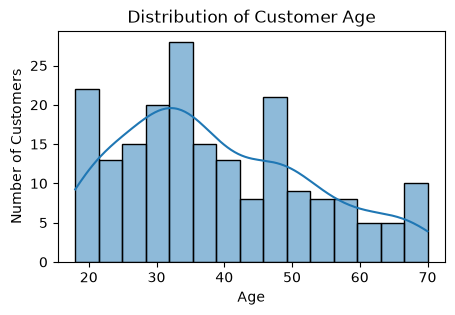

In [11]:
plt.figure(figsize=(5,3))
sns.histplot(customer_data['Age'], bins=15, kde=True)
plt.title('Distribution of Customer Age')
plt.xlabel('Age')
plt.ylabel('Number of Customers')
plt.show()

# Initial observation of datase t
dataset contains 200 customers and it has no duplicates and missing values. average age is around 39 years. there are slightly more females then males.

#### 2. Plot scatter plot for annual income and spending score which will be used for clustering in the next steps

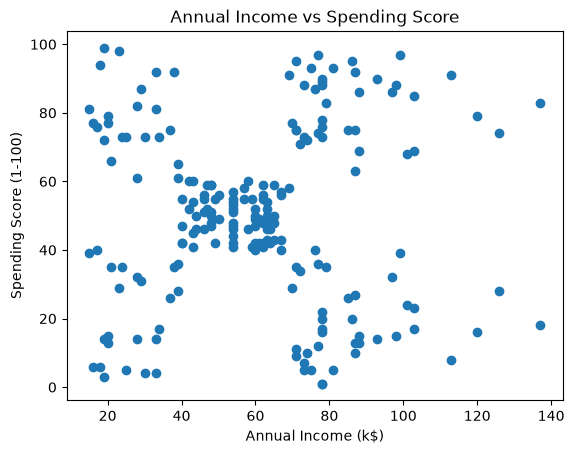

In [12]:
# <your code here>
plt.scatter(customer_data['Annual Income (k$)'], customer_data['Spending Score (1-100)'])
plt.title('Annual Income vs Spending Score')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.show()


#### 3. Normalize the data

In [25]:
# <your code here>

scaler= StandardScaler()
X= customer_data[['Annual Income (k$)','Spending Score (1-100)']]
X= scaler.fit_transform(X)

#### 4. Use Elbow method to decide number of clusters

In [18]:
# <your code here>

elbow=[]

for i in range(2,21):
    kmeans= KMeans(n_clusters=i, init='k-means++', random_state=555, max_iter=200)
    kmeans.fit(X)
    elbow.append(kmeans.inertia_)

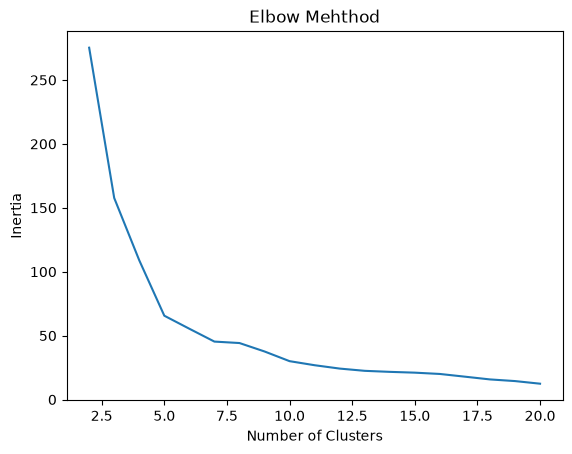

In [19]:
plt.plot(range(2,21),elbow)
plt.title('Elbow Mehthod')
plt.xlabel('Number of Clusters')
plt.ylabel('Inertia')
plt.show()

#### 5. Perform Clustering using KMeans

In [21]:
# <your code here>
k= 5
#i selected the number of clusters 5 because the elbow graph was bending around 5 value 
Cluster= KMeans(n_clusters=k, max_iter=200, random_state=555)
Cluster.fit(X)
y_pred= Cluster.predict(X)
y_pred

array([3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4,
       3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 2,
       3, 4, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 0, 1, 0, 2, 0, 1, 0, 1, 0,
       1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 2, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0,
       1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0,
       1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0,
       1, 0], dtype=int32)

#### 6. Plot scatter plot and color code in clustered groups

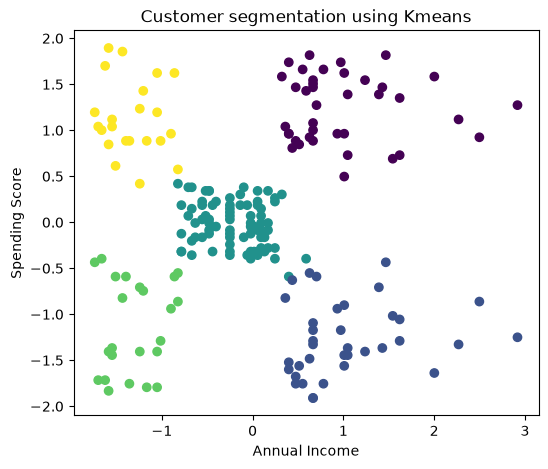

In [24]:
# <your code here>
plt.figure(figsize=(6,5))
plt.scatter(X[:,0], X[:, 1], c=y_pred, cmap= 'viridis')

plt.title('Customer segmentation using Kmeans')
plt.xlabel('Annual Income')
plt.ylabel('Spending Score')
plt.show()

#### 7. Plot dendrogram to decide number of clusters for Hierarchical Clustering. <br> Explain (free text in a markdown cell) what is the optimal number of clusters and why

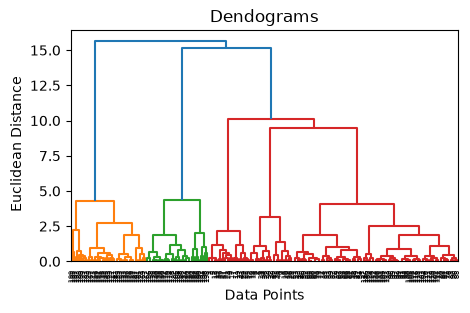

In [23]:
# <your code here>
import scipy.cluster.hierarchy as shc

plt.figure(figsize=(5,3))
plt.title('Dendograms')

dend= shc.dendrogram(shc.linkage(X,method='ward'))

plt.xlabel('Data Points')
plt.ylabel(' Euclidean Distance')
plt.show()


# Reasoning 
the optimal number of clusters is approximately 5 which can be identtified by drawing the horizontal cut through the dendogram at a distance where there is a large gap between clusterm merges. thats how we can see that the distance increases significantly from 4.5 to 9.7 and cutting the dendogram inside this gap give 5 distinct clsuters before they are merged in larger groups.

#### 8. Do clustering using Hierarchical Clustering

In [28]:
# <your code here>
from sklearn.cluster import AgglomerativeClustering

hc= AgglomerativeClustering(n_clusters=5, metric= 'euclidean', linkage='ward')
y_hc = hc.fit_predict(X)
y_hc

array([4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3,
       4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 2,
       4, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 1, 2, 1, 0, 1, 0, 1,
       2, 1, 0, 1, 0, 1, 0, 1, 0, 1, 2, 1, 0, 1, 2, 1, 0, 1, 0, 1, 0, 1,
       0, 1, 0, 1, 0, 1, 2, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1,
       0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1,
       0, 1])

#### 9. Plot scatter plot and color code in clustered groups

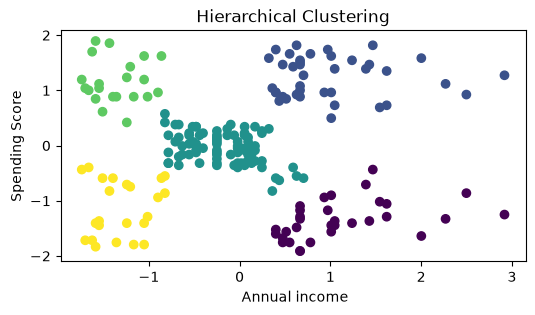

In [31]:
# <your code here>
plt.figure(figsize=(6,3))
plt.scatter(X[:,0], X[:,1],c= y_hc, cmap= 'viridis')
plt.title('Hierarchical Clustering')
plt.xlabel(' Annual income')
plt.ylabel('Spending Score')
plt.show()

####  10. Do KMeans and DBSCAN clustering on this data

In [32]:
from sklearn.datasets import make_moons
#moons_X: Data, moon_y: Labels
moons_X, moon_y = make_moons(n_samples=2000)

Text(0.5, 1.0, 'Half Moons')

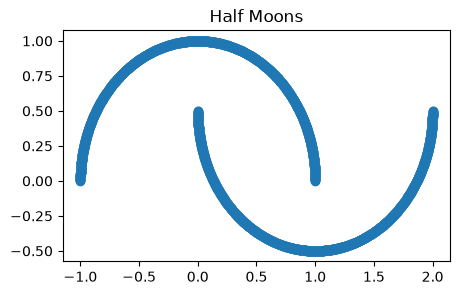

In [34]:
plt.figure(figsize=(5,3))
plt.scatter(moons_X[:,0],moons_X[:,1])
plt.title('Half Moons')

#### Using KMeans (do clustering and plot results (each cluster in own color))

In [36]:
# <your code here>
kmeans= KMeans(n_clusters=2, random_state=555)
yhat= kmeans.fit_predict(moons_X)
yhat


array([1, 0, 0, ..., 1, 1, 0], shape=(2000,), dtype=int32)

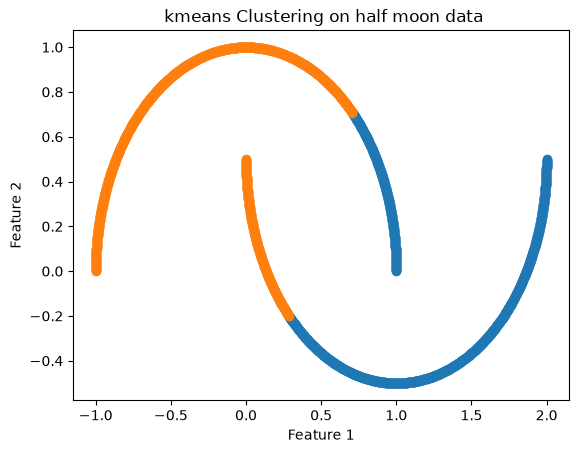

In [37]:
# <your code here>
clusters= np.unique(yhat)
for cluster in clusters:
    row_ix= np.where(yhat== cluster)
    plt.scatter(moons_X[row_ix,0], moons_X[row_ix,1])

plt.title(' kmeans Clustering on half moon data')
plt.xlabel('Feature 1')
plt.ylabel( 'Feature 2')
plt.show()

#### 11. Using DBSCAN do clustering and plot results (each cluster in own color). Find the most suitable eps and minimal samples number

In [58]:
# <your code here>
from sklearn.cluster import DBSCAN


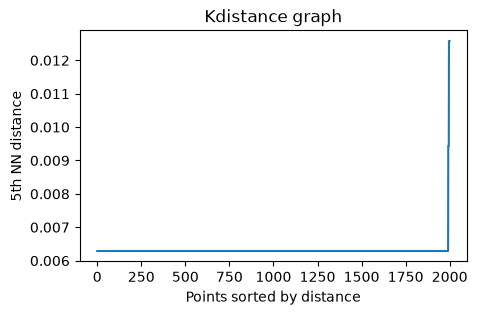

In [73]:
from sklearn.neighbors import NearestNeighbors
neigh= NearestNeighbors(n_neighbors=5)
neigh.fit(moons_X)

distances, indices= neigh.kneighbors(moons_X)
distances= np.sort(distances[:,4])
plt.figure(figsize=(5,3))
plt.plot(distances)
plt.title('Kdistance graph')
plt.xlabel('Points sorted by distance')
plt.ylabel('5th NN distance')
plt.show()

In [75]:
for eps in [0.0065,0.007,0.008,0.01,0.02,0.05,0.1,0.2]:
    model=DBSCAN(eps=eps, min_samples=5)
    yhat=model.fit_predict(moons_X)                        #Testing different eps values

    print( eps, np.unique(yhat, return_counts=True))

print (moons_X.min(axis=0))

0.0065 (array([0, 1]), array([1000, 1000]))
0.007 (array([0, 1]), array([1000, 1000]))
0.008 (array([0, 1]), array([1000, 1000]))
0.01 (array([0, 1]), array([1000, 1000]))
0.02 (array([0, 1]), array([1000, 1000]))
0.05 (array([0, 1]), array([1000, 1000]))
0.1 (array([0, 1]), array([1000, 1000]))
0.2 (array([0, 1]), array([1000, 1000]))
[-1.         -0.49999876]


the above kdistance graph which i produced to check the suitable eps value shows that there is a sharp increase in the distance to the 5th nearest neighbour near the end of sorted points. by testing different eps values while keeping min samples 5 it showed that all values prdouced two clusters. with that being said clustering result remained stable across different eps range

In [59]:
model = DBSCAN(eps= 0.2, min_samples=5)
yhat= model.fit_predict(moons_X)
clusters

array([0, 1])

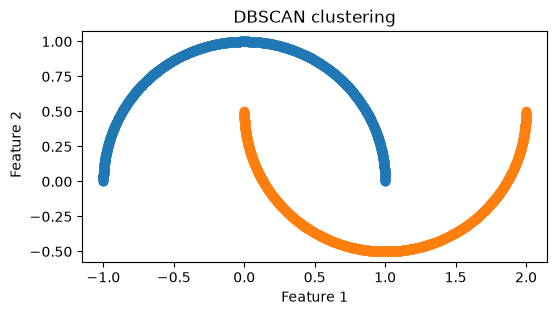

In [60]:
plt.figure(figsize=(6,3))
for cluster in clusters:
    m= yhat == cluster
    plt.scatter(moons_X[m,0], moons_X[m, 1], label= f'Cluster{cluster}')
    

plt.title('DBSCAN clustering')
plt.xlabel( 'Feature 1')
plt.ylabel(' Feature 2')
plt.show()

#### 12. Compare the results of K-means and DBSCAN clustering
Explain why one or another is prefferable for such dataset, and differences if any.

Kmeans and DBscan produced kind of different results on the half moon dataset. kmeans divided the data into two clusters but it did not correctly follow the original cuvred shapes it is because kmeans assures points based on their distances from cluster centroids. While DBSCAN performed better on this dataset without visible noise points with eps=2 and min samples 5 it identified both curved half moon structures as i understood from theory it is because it uses the density of neighboring points to form clusters thats why DBSCAN is prefferable for this dataset because it can figure irregular clusters instead of kmeans which is more suitable for clusters which are compact and clearly seperated.

### Perform PCA on penguins :)
###### This section uses kaggle dataset (https://www.kaggle.com/datasets/youssefaboelwafa/clustering-penguins-species/data)
###### The tasks below include data analysis, data preprocessing, PCA, and application of classification to predict the target

#### 13. Describe the data. Do any additional exporations as you feel

In [76]:
# Dataset
penguins = pd.read_csv('penguins.csv')
penguins.head()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,MALE
1,39.5,17.4,186.0,3800.0,FEMALE
2,40.3,18.0,195.0,3250.0,FEMALE
3,NaN,NaN,NaN,NaN,NaN
4,36.7,19.3,193.0,3450.0,FEMALE


In [80]:
# decribe the data, its size
# <your code here>
penguins.shape

(344, 5)

In [81]:
penguins.info()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   culmen_length_mm   342 non-null    float64
 1   culmen_depth_mm    342 non-null    float64
 2   flipper_length_mm  342 non-null    float64
 3   body_mass_g        342 non-null    float64
 4   sex                335 non-null    str    
dtypes: float64(4), str(1)
memory usage: 13.6 KB


In [82]:
penguins.describe()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,214.014620,4201.754386
std,5.459584,1.974793,260.558057,801.954536
min,32.100000,13.100000,-132.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.750000,4750.000000
max,59.600000,21.500000,5000.000000,6300.000000


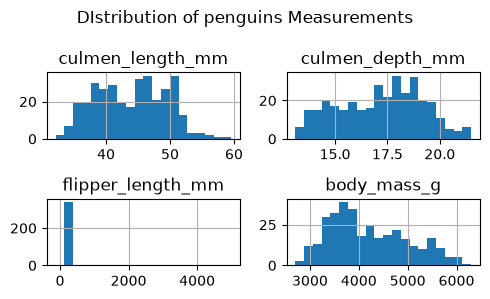

In [89]:
penguins.hist(figsize=(5,3), bins= 20)
plt.suptitle('DIstribution of penguins Measurements')
plt.tight_layout()
plt.show()

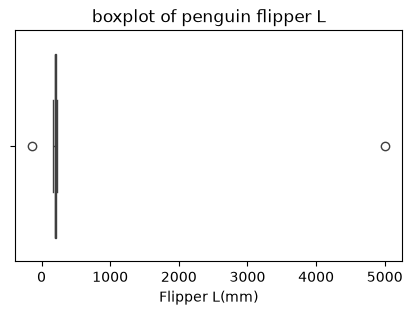

In [88]:
plt.figure(figsize=(5,3))
sns.boxplot(x=penguins['flipper_length_mm'])
plt.title('boxplot of penguin flipper L')
plt.xlabel('Flipper L(mm)')
plt.show()

#### Based on dataframe describe, in own words explain any abnormal characteristics 

# Observation
what i realized is that, well definitely according to dataset there are 344 rows and 5 columns including 4 numerical measurements and one categorical column(sex). what abnormality i found is that from .describe() it can be seen that minimum value of flipper length which is -132mm is very unrealistic and also on the other hand maximum value 5000mm is also not realistic. The dataset contains some missing values as well. apart from these other numerical features have reasonable ranges which can be seen from the Plots.

#### 14. Explore corrupted data

In [90]:
# find missing values. print entries with missing values, provide shape
# <your code here>

penguins.isnull().sum()

culmen_length_mm     2
culmen_depth_mm      2
flipper_length_mm    2
body_mass_g          2
sex                  9
dtype: int64

In [113]:
penguins[penguins.isnull().any(axis=1)]

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
3,NaN,NaN,NaN,NaN,NaN
8,34.1,18.1,193.0,3475.0,NaN
10,37.8,17.1,186.0,3300.0,NaN
11,37.8,17.3,180.0,3700.0,NaN
47,37.5,18.9,179.0,2975.0,NaN
246,44.5,14.3,216.0,4100.0,NaN
286,46.2,14.4,214.0,4650.0,NaN
324,47.3,13.8,216.0,4725.0,NaN
339,NaN,NaN,NaN,NaN,NaN


In [92]:
penguins[penguins.isnull().any(axis=1)].shape

(9, 5)

In [93]:
# Examine sex column
# <your code here>

penguins['sex'].value_counts(dropna=False)

sex
MALE      169
FEMALE    165
NaN         9
.           1
Name: count, dtype: int64

In [105]:
# find any unusual values. Print anomal rows
# <your code here>

penguins[(penguins['flipper_length_mm']<150) | (penguins['flipper_length_mm']>240)]

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
9,42.0,20.2,5000.0,4250.0,MALE
14,34.6,21.1,-132.0,4400.0,MALE


#### 15. Based on observations above, prepare the data for PCA. Only valid rows should be present. <br> Preview dataframe, show its size

In [128]:
# clean
# <your code here>
penguins_clean= penguins.dropna()
penguins_clean= penguins_clean[penguins_clean['sex'].isin(['MALE','FEMALE'])]
penguins_clean= penguins_clean[(penguins_clean['flipper_length_mm']>=150) & (penguins_clean['flipper_length_mm']<=240)]
penguins_clean.head()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,MALE
1,39.5,17.4,186.0,3800.0,FEMALE
2,40.3,18.0,195.0,3250.0,FEMALE
4,36.7,19.3,193.0,3450.0,FEMALE
5,39.3,20.6,190.0,3650.0,MALE


In [129]:
penguins_clean.shape

(332, 5)

In [135]:
# scale numerical columns. assign to a variable X_penguins
# <your code here>
scaler = StandardScaler()
X_penguins = scaler.fit_transform(penguins_clean.drop(columns='sex'))
X_penguins

array([[-0.90390586,  0.79035987, -1.42534179, -0.56694801],
       [-0.83043377,  0.12618674, -1.0685765 , -0.50484747],
       [-0.68348959,  0.43272819, -0.42639899, -1.18795343],
       ...,
       [ 1.17168063, -0.74234736,  1.50013355,  1.91707363],
       [ 0.21654349, -1.20215952,  0.78660298,  1.23396768],
       [ 1.07984052, -0.53798639,  0.85795603,  1.48236985]],
      shape=(332, 4))

In [137]:
# assign categorical column to a variable y_penguins
# <your code here>

y_penguins= penguins_clean['sex']
y_penguins

0        MALE
1      FEMALE
2      FEMALE
4      FEMALE
5        MALE
        ...  
338    FEMALE
340    FEMALE
341      MALE
342    FEMALE
343      MALE
Name: sex, Length: 332, dtype: str

#### 15. Explain the chosen null values handling strategy, how it affects the dataset (pros/cons)

# strategy explanationn
i removed rows containing missing values using dropna() rather than filling them with estimated values which kept the original measurements unchanged. With that the advantage is working with complete observations, which made the data prep straightforward. well however removing rows reduced the dataset size and it can cause information loss especially when several values are missing. I also removed the invalid sex entry and two unrealistic flipper lengths to make sure that only valid observations are used for PCA and after that dataset contained 332 rows and 5 columns. i used scaling for 4 numerical features and stored in X_penguins an categorical sex column in y_penguins.

#### 16. Perform PCA with 2 components. Plot the results 

In [140]:
# <your code here>

pca= PCA(n_components=2)
X_pca= pca.fit_transform(X_penguins)
X_pca.shape

(332, 2)

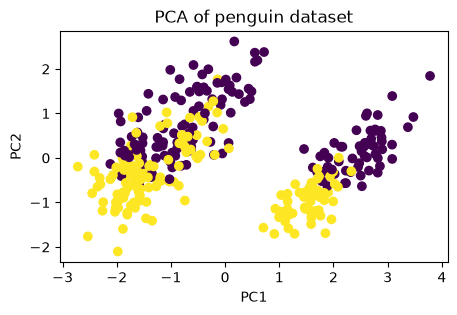

In [144]:
plt.figure(figsize=(5,3))
plt.scatter(X_pca[:,0], X_pca[:,1], c=pd.factorize(y_penguins)[0],cmap='viridis')
plt.title('PCA of penguin dataset')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()



# analysis
scatter plot shows grouping between male and female penguins but there is still overlap between two categories whihc means the first 2 components preserve usefull information from the original measurements but they do not completely separate the categories.

#### 17. Display scree plots to determine the optimal number of components and cumulative explained variance

In [145]:
# <your code here>

pca= PCA()
X_pca= pca.fit_transform(X_penguins)
explained_var= pca.explained_variance_ratio_
explained_var

array([0.68713344, 0.19641564, 0.08951723, 0.0269337 ])

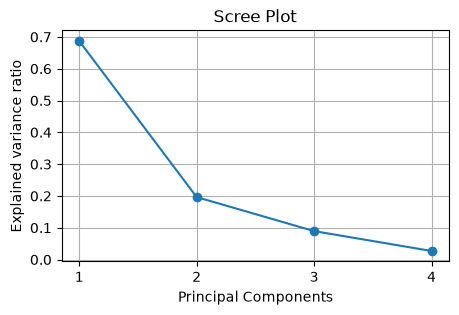

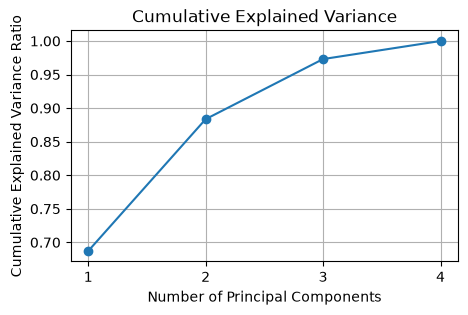

In [149]:
plt.figure(figsize=(5,3))
plt.plot(range(1,len(explained_var)+1),explained_var, marker= 'o')
plt.title('Scree Plot')
plt.xlabel('Principal Components')
plt.ylabel('Explained variance ratio')          #scree Plot
plt.xticks(range(1,5))
plt.grid()
plt.show()

cummulative_variance= np.cumsum(explained_var)
plt.figure(figsize=(5,3))
plt.plot(range(1, len(cummulative_variance) + 1), cummulative_variance, marker='o')         #cummulative explained var
plt.title('Cumulative Explained Variance')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance Ratio')
plt.xticks(range(1, 5))
plt.grid()
plt.show()


#### 18. Calculate (show in numbers) and display component loadings

In [151]:
# Component loadings (how much each original feature contributes to each PC)
# <your code here>
loadings= pca.components_.T * np.sqrt(pca.explained_variance_)
loadings_df= pd.DataFrame(
    loadings,
    columns= ['PC1', 'PC2', 'PC3', 'PC4'],
    index= penguins_clean.drop('sex',axis=1).columns
)
loadings_df

,PC1,PC2,PC3,PC4
culmen_length_mm,0.752437,0.537058,0.382172,-0.048704
culmen_depth_mm,-0.661689,0.703921,-0.258543,0.053291
flipper_length_mm,0.957835,0.003371,-0.138774,0.257494
body_mass_g,0.913999,0.063944,-0.356360,-0.191168


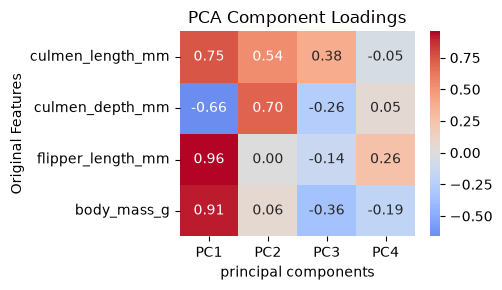

In [152]:
# show heatmap
# <your code here>
plt.figure(figsize=(5,3))
sns.heatmap(loadings_df, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('PCA Component Loadings')
plt.xlabel('principal components')
plt.ylabel('Original Features')
plt.tight_layout()
plt.show()

# Observvation
from the component loadings above i observed that pc1 is mainly influenced by flipper L(mm), body mass and culmen L. while culmen depth gave negative contribution. pc2 influenced by culmen depth and culmen length. With those i figured that pc1 represent differences related to mainly its body size but pc2 gets more variation in beak measurements. heatmap helped identifying these.

#### 19. Perform logistic regression (or any other classification algorithm) and evaluate the model

In [153]:
# import necessary libraries for model training and evaluation
# Use the PCA-transformed data (X_penguins_pca) and true labels (y_penguins)
# Train and evaluate a model
# <your code here>
pca= PCA(n_components=2)
X_penguins_pca= pca.fit_transform(X_penguins)

In [164]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
X_train, X_test, y_train, y_test = train_test_split(
    X_penguins_pca, y_penguins, test_size=0.30, random_state=101)

In [165]:
clf= LogisticRegression(max_iter=200)
clf.fit(X_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",200
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in

In [166]:
y_pred= clf.predict(X_test)

print("Accuracy:", accuracy_score(y_test,y_pred))
print( classification_report(y_test,y_pred))

Accuracy: 0.79
              precision    recall  f1-score   support

      FEMALE       0.76      0.77      0.76        44
        MALE       0.82      0.80      0.81        56

    accuracy                           0.79       100
   macro avg       0.79      0.79      0.79       100
weighted avg       0.79      0.79      0.79       100



#### 20. Train the model on all data points, and determine penguin sex for the data, where it was not originally identified

In [176]:
# 1. take entries from original data with sex unknown, scale numerical columns
# <your code here>
penguins_unknown= penguins [penguins['sex'].isnull()].dropna(subset=[
    'culmen_length_mm', 'culmen_depth_mm',
    'flipper_length_mm', 'body_mass_g'

    ])
X_unknown= scaler.transform(penguins_unknown.drop('sex',axis=1))

penguins_unknown



,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
8,34.1,18.1,193.0,3475.0,NaN
10,37.8,17.1,186.0,3300.0,NaN
11,37.8,17.3,180.0,3700.0,NaN
47,37.5,18.9,179.0,2975.0,NaN
246,44.5,14.3,216.0,4100.0,NaN
286,46.2,14.4,214.0,4650.0,NaN
324,47.3,13.8,216.0,4725.0,NaN


In [177]:
# 2. apply the same PCA transformation to the new data
# <your code here>

X_unknown_pca= pca.transform(X_unknown)


In [179]:
# 3. Train the model
# Define X_train and y_train using all PCA data from valid data
# <your code here>

X_train= X_penguins_pca
y_train= y_penguins

# Train a classifier
# <your code here>

clf= LogisticRegression(max_iter=200)
clf.fit(X_train,y_train)


,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",200
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in

In [180]:
# 4. Make predictions on the new data. Display the features and predicted values
# <your code here>

y_unknown_pred= clf.predict(X_unknown_pca)
penguins_unknown['predicted_sex']= y_unknown_pred

penguins_unknown




,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex,predicted_sex
8,34.1,18.1,193.0,3475.0,NaN,FEMALE
10,37.8,17.1,186.0,3300.0,NaN,FEMALE
11,37.8,17.3,180.0,3700.0,NaN,FEMALE
47,37.5,18.9,179.0,2975.0,NaN,FEMALE
246,44.5,14.3,216.0,4100.0,NaN,FEMALE
286,46.2,14.4,214.0,4650.0,NaN,FEMALE
324,47.3,13.8,216.0,4725.0,NaN,FEMALE


In [181]:
pd.Series(y_pred).value_counts()

MALE      55
FEMALE    45
Name: count, dtype: int64

In [182]:
from sklearn.metrics import confusion_matrix
confusion_matrix(y_test,y_pred, labels=['FEMALE','MALE'])

array([[34, 10],
       [11, 45]])

# observation
from the model trained it predicted all 7 penguins with missing sex as female. to further diving into the predictions I checked the confusion matrix using labeled test data. Model correctly classified 34 females and 45 males with 21 incorrect prediction like False positive and False negatives therefore the test accuracy was 79%.